In [1]:
import sys
print(sys.executable)

import numpy as np
import pandas as pd

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

c:\Users\Lenovo\Desktop\mobile-ux-research\.venv\Scripts\python.exe
NumPy: 2.4.6
Pandas: 3.1.0


In [2]:
import sys
print(sys.executable)

import numpy as np
import pandas as pd

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

c:\Users\Lenovo\Desktop\mobile-ux-research\.venv\Scripts\python.exe
NumPy: 2.4.6
Pandas: 3.1.0


In [3]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

np.random.seed(42)

CURRENT = Path.cwd()

ROOT = next(
    (p for p in [CURRENT, *CURRENT.parents]
     if (p / "data" / "raw" / "test_run.jsonl").exists()),
    None
)

if ROOT is None:
    raise FileNotFoundError(
        "Cannot find data/raw/test_run.jsonl. Check the project folders."
    )

RAW_FILE = ROOT / "data" / "raw" / "test_run.jsonl"

print("Project folder:", ROOT)
print("Data file exists:", RAW_FILE.exists())

Project folder: c:\Users\Lenovo\Desktop\mobile-ux-research
Data file exists: True


In [4]:
records = []

with open(RAW_FILE, "r", encoding="utf-8") as file:
    for line in file:
        if line.strip():
            records.append(json.loads(line))

df = pd.DataFrame(records)

print("Total records:", len(df))
df.head()

Total records: 8


,user_id,interface,run_type,task_time_seconds,task_success,error_count,satisfaction
0,1,baseline,warmup,35.0,1,2,3
1,1,baseline,evaluation,25.4,1,1,3
2,2,baseline,evaluation,28.1,1,0,3
3,3,baseline,evaluation,31.2,0,2,2
4,1,improved,warmup,29.0,1,1,4


In [5]:
df = df[df["run_type"] == "evaluation"].copy()

print("Records after removing warm-up:", len(df))
df.head()

Records after removing warm-up: 6


,user_id,interface,run_type,task_time_seconds,task_success,error_count,satisfaction
1,1,baseline,evaluation,25.4,1,1,3
2,2,baseline,evaluation,28.1,1,0,3
3,3,baseline,evaluation,31.2,0,2,2
5,1,improved,evaluation,19.7,1,0,4
6,2,improved,evaluation,21.3,1,0,5


In [6]:
print("Records by interface:")
print(df["interface"].value_counts())

print("\nAvailable columns:")
print(df.columns.tolist())

Records by interface:
interface
baseline    3
improved    3
Name: count, dtype: int64

Available columns:
['user_id', 'interface', 'run_type', 'task_time_seconds', 'task_success', 'error_count', 'satisfaction']


In [7]:
numeric_columns = [
    "task_time_seconds",
    "task_success",
    "error_count",
    "satisfaction"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

df = df.dropna(subset=numeric_columns)

df = df[
    (df["task_time_seconds"] > 0) &
    (df["task_success"].isin([0, 1])) &
    (df["error_count"] >= 0) &
    (df["satisfaction"].between(1, 5)) &
    (df["interface"].isin(["baseline", "improved"]))
].copy()

print("Valid records:", len(df))
print("Interfaces:", df["interface"].unique())

Valid records: 6
Interfaces: <StringArray>
['baseline', 'improved']
Length: 2, dtype: str


In [8]:
summary = df.groupby("interface").agg(
    sample_size=("task_time_seconds", "count"),
    mean_time=("task_time_seconds", "mean"),
    std_time=("task_time_seconds", "std"),
    median_time=("task_time_seconds", "median"),
    p95_time=("task_time_seconds", lambda x: x.quantile(0.95)),
    p99_time=("task_time_seconds", lambda x: x.quantile(0.99)),
    success_rate=("task_success", "mean"),
    error_rate=("error_count", lambda x: (x > 0).mean()),
    mean_errors=("error_count", "mean"),
    satisfaction=("satisfaction", "mean")
).reset_index()

summary

,interface,sample_size,mean_time,std_time,median_time,p95_time,p99_time,success_rate,error_rate,mean_errors,satisfaction
0,baseline,3,28.233333,2.902298,28.1,30.89,31.138,0.666667,0.666667,1.000000,2.666667
1,improved,3,20.366667,0.832666,20.1,21.18,21.276,1.000000,0.333333,0.333333,4.333333


In [9]:
def bootstrap_ci(values, iterations=5000):
    values = np.asarray(values, dtype=float)
    rng = np.random.default_rng(42)

    bootstrap_means = []

    for _ in range(iterations):
        sample = rng.choice(
            values,
            size=len(values),
            replace=True
        )
        bootstrap_means.append(np.mean(sample))

    lower = np.percentile(bootstrap_means, 2.5)
    upper = np.percentile(bootstrap_means, 97.5)

    return lower, upper


for interface in ["baseline", "improved"]:
    values = df.loc[
        df["interface"] == interface,
        "task_time_seconds"
    ].to_numpy()

    lower, upper = bootstrap_ci(values)

    print(f"{interface}:")
    print(f"95% CI: {lower:.2f} – {upper:.2f} seconds\n")

baseline:
95% CI: 25.40 – 31.20 seconds

improved:
95% CI: 19.70 – 21.30 seconds



In [10]:
user_times = df.pivot_table(
    index="user_id",
    columns="interface",
    values="task_time_seconds",
    aggfunc="mean"
).dropna(subset=["baseline", "improved"])

if len(user_times) >= 2:
    test_result = stats.ttest_rel(
        user_times["baseline"],
        user_times["improved"],
        alternative="greater"
    )

    print("Number of paired participants:", len(user_times))
    print("T-statistic:", test_result.statistic)
    print("P-value:", test_result.pvalue)

    if test_result.pvalue < 0.05:
        print("Reject H0. Evidence supports H1.")
    else:
        print("Fail to reject H0. Not enough evidence for H1.")
else:
    print("Not enough paired participants for the test.")

Number of paired participants: 3
T-statistic: 4.7747459550990525
P-value: 0.02058656111199968
Reject H0. Evidence supports H1.


In [11]:
OUTPUT_FILE = ROOT / "data" / "processed" / "metrics_summary.csv"

OUTPUT_FILE.parent.mkdir(parents=True, exist_ok=True)

summary.to_csv(OUTPUT_FILE, index=False)

print("Analysis completed!")
print("Results saved to:", OUTPUT_FILE)

summary

Analysis completed!
Results saved to: c:\Users\Lenovo\Desktop\mobile-ux-research\data\processed\metrics_summary.csv


,interface,sample_size,mean_time,std_time,median_time,p95_time,p99_time,success_rate,error_rate,mean_errors,satisfaction
0,baseline,3,28.233333,2.902298,28.1,30.89,31.138,0.666667,0.666667,1.000000,2.666667
1,improved,3,20.366667,0.832666,20.1,21.18,21.276,1.000000,0.333333,0.333333,4.333333


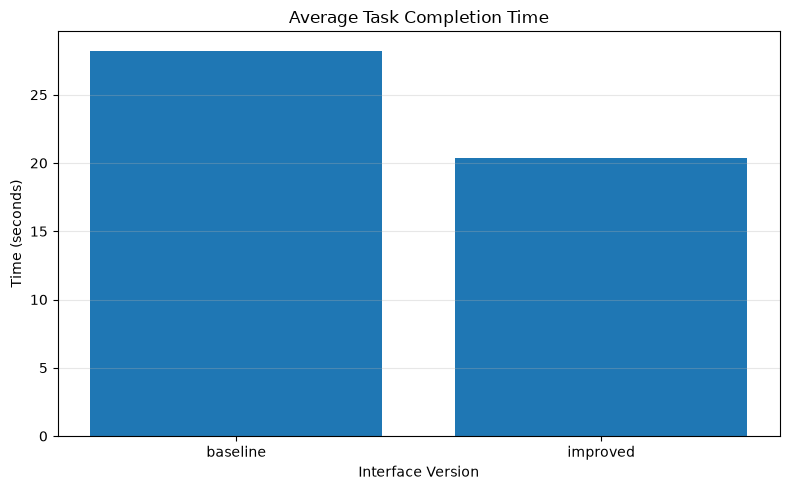

In [12]:
plt.figure(figsize=(8, 5))

plt.bar(
    summary["interface"],
    summary["mean_time"]
)

plt.title("Average Task Completion Time")
plt.xlabel("Interface Version")
plt.ylabel("Time (seconds)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()